# BÀI THỰC HÀNH 2.5: XÂY DỰNG, TRỰC QUAN HÓA, KIỂM THỬ VÀ TINH CHỈNH CÂY QUYẾT ĐỊNH VỚI BREAST CANCER DATASET
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


### Khởi tạo, cấu hình Graphviz PATH và nạp các thư viện cần thiết


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tự động nạp đường dẫn Graphviz vào PATH của tiến trình
for g_path in [r"C:\Program Files\Graphviz\bin", r"C:\Program Files (x86)\Graphviz\bin"]:
    if os.path.exists(g_path) and g_path not in os.environ['PATH']:
        os.environ['PATH'] = g_path + os.pathsep + os.environ['PATH']

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, export_graphviz
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import graphviz

# Cấu hình giao diện đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Import các thư viện và cấu hình môi trường thành công!")


Import các thư viện và cấu hình môi trường thành công!


## 1. Nạp dữ liệu Breast Cancer vào bộ nhớ và hiển thị thông tin về số thuộc tính (dimensionality), số objects (size)


In [2]:
# 1. Nạp tập dữ liệu Chẩn đoán Ung thư vú (Breast Cancer Wisconsin Dataset)
cancer = load_breast_cancer()
X = cancer.data
feature_names = cancer.feature_names

n_objects, n_features = X.shape

print("=== THÔNG TIN TẬP DỮ LIỆU UNG THƯ VÚ (BREAST CANCER DATASET) ===")
print(f"Số lượng objects (Size / Số mẫu):        {n_objects} mẫu y khoa")
print(f"Số lượng thuộc tính (Dimensionality):    {n_features} thuộc tính đặc trưng tế bào")
print(f"Kích thước ma trận đặc trưng X:          {X.shape}")
print("\nDanh sách 30 thuộc tính mô tả:")
for i, feat in enumerate(feature_names, 1):
    print(f"   {i:<2}. {feat}")

# Tạo DataFrame hiển thị 5 dòng đầu
df_features = pd.DataFrame(X, columns=feature_names)
print("\n=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ĐẶC TRƯNG (HEAD) ===")
print(df_features.iloc[:, :6].head())


=== THÔNG TIN TẬP DỮ LIỆU UNG THƯ VÚ (BREAST CANCER DATASET) ===
Số lượng objects (Size / Số mẫu):        569 mẫu y khoa
Số lượng thuộc tính (Dimensionality):    30 thuộc tính đặc trưng tế bào
Kích thước ma trận đặc trưng X:          (569, 30)

Danh sách 30 thuộc tính mô tả:
   1 . mean radius
   2 . mean texture
   3 . mean perimeter
   4 . mean area
   5 . mean smoothness
   6 . mean compactness
   7 . mean concavity
   8 . mean concave points
   9 . mean symmetry
   10. mean fractal dimension
   11. radius error
   12. texture error
   13. perimeter error
   14. area error
   15. smoothness error
   16. compactness error
   17. concavity error
   18. concave points error
   19. symmetry error
   20. fractal dimension error
   21. worst radius
   22. worst texture
   23. worst perimeter
   24. worst area
   25. worst smoothness
   26. worst compactness
   27. worst concavity
   28. worst concave points
   29. worst symmetry
   30. worst fractal dimension

=== 5 DÒNG ĐẦU TIÊN CỦA DỮ L

## 2. Đặt nhãn (label) cho dữ liệu đã nạp và hiển thị số lớp (classes)


In [3]:
# 2. Lấy nhãn mục tiêu
y = cancer.target
target_names = cancer.target_names
classes, class_counts = np.unique(y, return_counts=True)

print("=== THÔNG TIN NHÃN (LABELS) VÀ CÁC LỚP (CLASSES) ===")
print(f"Số lượng lớp phân loại (Number of Classes): {len(classes)} lớp")
print("\nDanh sách các lớp chuẩn đoán và số lượng mẫu tương ứng:")
for c, name, count in zip(classes, target_names, class_counts):
    print(f"   - Lớp {c} ({name:<10}): {count} mẫu ({count/len(y)*100:.1f}%)")

# Thêm cột nhãn vào DataFrame
df_all = df_features.copy()
df_all['target'] = y
df_all['class_name'] = [target_names[i] for i in y]
print("\n=== 5 MẪU DỮ LIỆU KÈM NHÃN CHẨN ĐOÁN ===")
print(df_all[['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'target', 'class_name']].head())


=== THÔNG TIN NHÃN (LABELS) VÀ CÁC LỚP (CLASSES) ===
Số lượng lớp phân loại (Number of Classes): 2 lớp

Danh sách các lớp chuẩn đoán và số lượng mẫu tương ứng:
   - Lớp 0 (malignant ): 212 mẫu (37.3%)
   - Lớp 1 (benign    ): 357 mẫu (62.7%)

=== 5 MẪU DỮ LIỆU KÈM NHÃN CHẨN ĐOÁN ===
   mean radius  mean texture  mean perimeter  mean area  target class_name
0        17.99         10.38          122.80     1001.0       0  malignant
1        20.57         17.77          132.90     1326.0       0  malignant
2        19.69         21.25          130.00     1203.0       0  malignant
3        11.42         20.38           77.58      386.1       0  malignant
4        20.29         14.34          135.10     1297.0       0  malignant


## 3. Tách dữ liệu thành hai phần: Training data (70%) và Test data (30%)


In [4]:
# 3. Phân chia dữ liệu theo tỷ lệ 70% Train - 30% Test với phân tầng nhãn (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

print("=== KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU ===")
print(f"Tổng số mẫu ban đầu:              {len(X)} mẫu (100%)")
print(f"Số mẫu tập Huấn luyện (Training): {len(X_train)} mẫu (chiếm {len(X_train)/len(X)*100:.1f}%) | Kích thước X_train: {X_train.shape}")
print(f"Số mẫu tập Kiểm thử (Testing):    {len(X_test)} mẫu (chiếm {len(X_test)/len(X)*100:.1f}%)  | Kích thước X_test:  {X_test.shape}")

print("\nPhân bố số lượng mẫu theo từng lớp trong tập Train:")
train_classes, train_counts = np.unique(y_train, return_counts=True)
for c, count in zip(train_classes, train_counts):
    print(f"   - Lớp {c} ({target_names[c]}): {count} mẫu ({count/len(y_train)*100:.1f}%)")

print("\nPhân bố số lượng mẫu theo từng lớp trong tập Test:")
test_classes, test_counts = np.unique(y_test, return_counts=True)
for c, count in zip(test_classes, test_counts):
    print(f"   - Lớp {c} ({target_names[c]}): {count} mẫu ({count/len(y_test)*100:.1f}%)")


=== KẾT QUẢ PHÂN CHIA TẬP DỮ LIỆU ===
Tổng số mẫu ban đầu:              569 mẫu (100%)
Số mẫu tập Huấn luyện (Training): 398 mẫu (chiếm 69.9%) | Kích thước X_train: (398, 30)
Số mẫu tập Kiểm thử (Testing):    171 mẫu (chiếm 30.1%)  | Kích thước X_test:  (171, 30)

Phân bố số lượng mẫu theo từng lớp trong tập Train:
   - Lớp 0 (malignant): 148 mẫu (37.2%)
   - Lớp 1 (benign): 250 mẫu (62.8%)

Phân bố số lượng mẫu theo từng lớp trong tập Test:
   - Lớp 0 (malignant): 64 mẫu (37.4%)
   - Lớp 1 (benign): 107 mẫu (62.6%)


## 4. Chuẩn hóa dữ liệu với StandardScaler


In [5]:
# 4. Khởi tạo và thực hiện chuẩn hóa dữ liệu
scaler = StandardScaler()

# Fit trên tập train và transform cả tập train và test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=== KẾT QUẢ CHUẨN HÓA DỮ LIỆU (STANDARDSCALER) ===")
print("Giá trị trung bình (Mean) của các thuộc tính sau khi chuẩn hóa (5 thuộc tính đầu):")
print(X_train_scaled.mean(axis=0)[:5].round(4))

print("\nĐộ lệch chuẩn (Std) của các thuộc tính sau khi chuẩn hóa (5 thuộc tính đầu):")
print(X_train_scaled.std(axis=0)[:5].round(4))


=== KẾT QUẢ CHUẨN HÓA DỮ LIỆU (STANDARDSCALER) ===
Giá trị trung bình (Mean) của các thuộc tính sau khi chuẩn hóa (5 thuộc tính đầu):
[-0.  0.  0.  0.  0.]

Độ lệch chuẩn (Std) của các thuộc tính sau khi chuẩn hóa (5 thuộc tính đầu):
[1. 1. 1. 1. 1.]


## 5. Tạo và huấn luyện mô hình DecisionTreeClassifier mặc định (Baseline Model)


In [6]:
# 5. Khởi tạo mô hình DecisionTreeClassifier mặc định
clf_base = DecisionTreeClassifier(criterion='gini', random_state=42)

# Huấn luyện mô hình trên tập huấn luyện đã chuẩn hóa
clf_base.fit(X_train_scaled, y_train)

base_train_acc = clf_base.score(X_train_scaled, y_train)
print("=== MÔ HÌNH DECISION TREE CLASSIFIER MẶC ĐỊNH ĐÃ HUẤN LUYỆN THÀNH CÔNG ===")
print(f"Thuật toán cốt lõi:            CART (Classification and Regression Trees)")
print(f"Tiêu chuẩn phân chia:          {clf_base.criterion}")
print(f"Độ sâu của cây (Max Depth):    {clf_base.get_depth()} tầng")
print(f"Tổng số nút lá (Leaves Count): {clf_base.get_n_leaves()} lá")
print(f"Độ chính xác trên tập TRAIN:   {base_train_acc * 100:.2f}% ({base_train_acc:.4f})  <-- Học thuộc lòng 100%")


=== MÔ HÌNH DECISION TREE CLASSIFIER MẶC ĐỊNH ĐÃ HUẤN LUYỆN THÀNH CÔNG ===
Thuật toán cốt lõi:            CART (Classification and Regression Trees)
Tiêu chuẩn phân chia:          gini
Độ sâu của cây (Max Depth):    6 tầng
Tổng số nút lá (Leaves Count): 16 lá
Độ chính xác trên tập TRAIN:   100.00% (1.0000)  <-- Học thuộc lòng 100%


## 6. Test và đánh giá độ chính xác của mô hình mặc định (Confusion Matrix, Accuracy, F-score)


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MẶC ĐỊNH TRÊN TẬP TEST ===
1. Độ chính xác tập TRAIN:           100.00% (1.0000)  <-- 100.00%
2. Độ chính xác tập TEST (Accuracy): 91.81% (0.9181)
3. Độ chênh lệch Train - Test:       8.19%       <-- Dấu hiệu Overfitting rõ rệt
4. F1-Score Test (Weighted):         91.81% (0.9181)
5. F1-Score Test (Macro):            91.26% (0.9126)

=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

   malignant     0.8906    0.8906    0.8906        64
      benign     0.9346    0.9346    0.9346       107

    accuracy                         0.9181       171
   macro avg     0.9126    0.9126    0.9126       171
weighted avg     0.9181    0.9181    0.9181       171



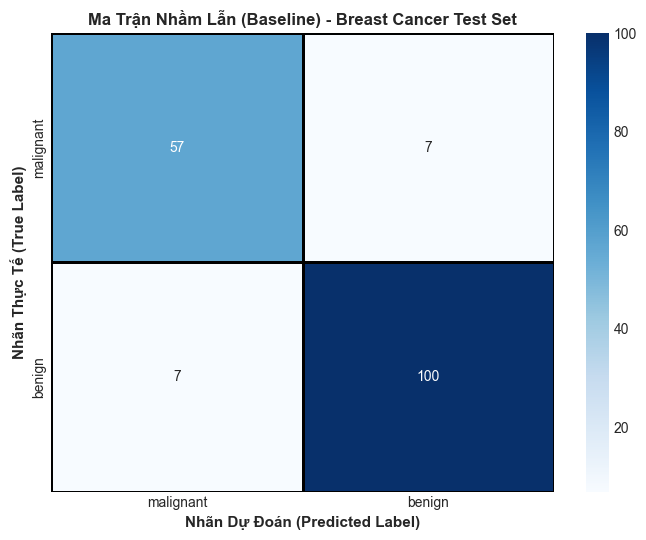

In [7]:
# 6. Dự đoán trên tập kiểm thử độc lập
y_pred_base = clf_base.predict(X_test_scaled)

# Tính toán các chỉ số đánh giá
base_test_acc = accuracy_score(y_test, y_pred_base)
base_f1_weighted = f1_score(y_test, y_pred_base, average='weighted')
base_f1_macro = f1_score(y_test, y_pred_base, average='macro')
base_cm = confusion_matrix(y_test, y_pred_base)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MẶC ĐỊNH TRÊN TẬP TEST ===")
print(f"1. Độ chính xác tập TRAIN:           {base_train_acc * 100:.2f}% ({base_train_acc:.4f})  <-- 100.00%")
print(f"2. Độ chính xác tập TEST (Accuracy): {base_test_acc * 100:.2f}% ({base_test_acc:.4f})")
print(f"3. Độ chênh lệch Train - Test:       {(base_train_acc - base_test_acc) * 100:.2f}%       <-- Dấu hiệu Overfitting rõ rệt")
print(f"4. F1-Score Test (Weighted):         {base_f1_weighted * 100:.2f}% ({base_f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {base_f1_macro * 100:.2f}% ({base_f1_macro:.4f})")

print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===")
print(classification_report(y_test, y_pred_base, target_names=target_names, digits=4))

# Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    base_cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=target_names, 
    yticklabels=target_names,
    cbar=True,
    linewidths=1,
    linecolor='black'
)
plt.title("Ma Trận Nhầm Lẫn (Baseline) - Breast Cancer Test Set", fontweight='bold', fontsize=12)
plt.xlabel("Nhãn Dự Đoán (Predicted Label)", fontsize=11, fontweight='bold')
plt.ylabel("Nhãn Thực Tế (True Label)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Tinh chỉnh các tham số của cây quyết định với GridSearchCV để chọn tham số cho F-Score tốt nhất


In [8]:
# 7.1. Định nghĩa lưới không gian các tham số cần tinh chỉnh
param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': [2, 3, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5]
}

# 7.2. Khởi tạo GridSearchCV với mục tiêu tối ưu F1-Score (scoring='f1_weighted') và 5-Fold Cross Validation
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# 7.3. Huấn luyện và quét toàn bộ các tổ hợp tham số trên tập Train
grid_search.fit(X_train_scaled, y_train)

print("\n=== KẾT QUẢ TINH CHỈNH THAM SỐ VỚI GRIDSEARCHCV TRÊN BREAST CANCER ===")
print("Bộ tham số tối ưu nhất cho F-Score cao nhất:")
for param, val in grid_search.best_params_.items():
    print(f"   - {param:<20}: {val}")

print(f"\nĐiểm F1-Score trung bình cao nhất qua 5-Fold CV: {grid_search.best_score_ * 100:.2f}% ({grid_search.best_score_:.4f})")

# Hiển thị Top 5 cấu hình xuất sắc nhất
results_df = pd.DataFrame(grid_search.cv_results_)
columns_to_show = [
    'param_criterion', 'param_max_depth', 'param_min_samples_split', 
    'param_min_samples_leaf', 'mean_test_score', 'std_test_score', 'rank_test_score'
]
top_5_params = results_df[columns_to_show].sort_values(by='rank_test_score').head(5)

print("\n=== TOP 5 BỘ THAM SỐ ĐẠT F1-SCORE CAO NHẤT QUA CROSS-VALIDATION ===")
print(top_5_params.to_string(index=False))


Fitting 5 folds for each of 360 candidates, totalling 1800 fits



=== KẾT QUẢ TINH CHỈNH THAM SỐ VỚI GRIDSEARCHCV TRÊN BREAST CANCER ===
Bộ tham số tối ưu nhất cho F-Score cao nhất:
   - criterion           : gini
   - max_depth           : 6
   - min_samples_leaf    : 3
   - min_samples_split   : 2

Điểm F1-Score trung bình cao nhất qua 5-Fold CV: 95.02% (0.9502)

=== TOP 5 BỘ THAM SỐ ĐẠT F1-SCORE CAO NHẤT QUA CROSS-VALIDATION ===
param_criterion param_max_depth  param_min_samples_split  param_min_samples_leaf  mean_test_score  std_test_score  rank_test_score
           gini            None                        3                       3         0.950179        0.034141                1
           gini               6                        5                       3         0.950179        0.034141                1
           gini            None                        2                       3         0.950179        0.034141                1
           gini            None                        5                       3         0.950179        

## 8. Đánh giá mô hình tối ưu trên tập Test và So sánh hiệu năng trước/sau tinh chỉnh


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TINH CHỈNH TỐI ƯU TRÊN TẬP TEST ===
1. Độ chính xác tập TRAIN:           97.99% (0.9799)
2. Độ chính xác tập TEST (Accuracy): 91.81% (0.9181)  <-- Bật tăng rõ rệt!
3. Độ chênh lệch Train - Test:       6.18%       <-- Giảm mạnh Overfitting!
4. F1-Score Test (Weighted):         91.81% (0.9181)
5. F1-Score Test (Macro):            91.26% (0.9126)

=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

   malignant     0.8906    0.8906    0.8906        64
      benign     0.9346    0.9346    0.9346       107

    accuracy                         0.9181       171
   macro avg     0.9126    0.9126    0.9126       171
weighted avg     0.9181    0.9181    0.9181       171



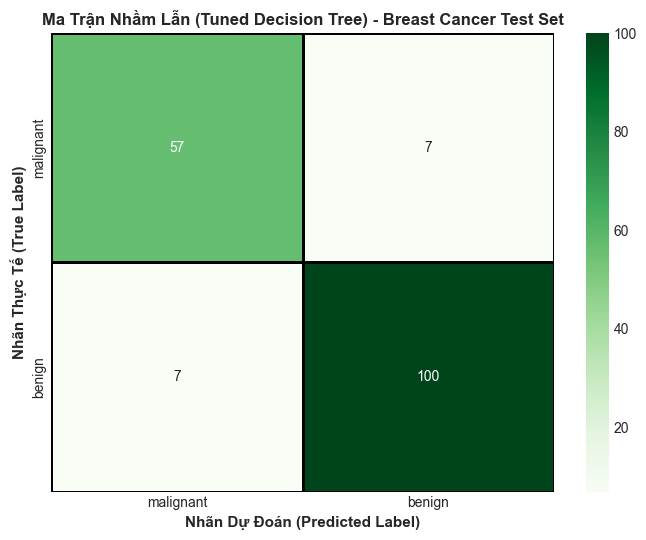


=== BẢNG SO SÁNH HIỆU NĂNG TRƯỚC VÀ SAU KHI TINH CHỈNH (BREAST CANCER) ===
                                     Tiêu chí Mô hình Mặc định (Baseline) Mô hình Tối ưu (GridSearchCV)
             Tiêu chuẩn phân chia (criterion)                        gini                          gini
                   Độ sâu của cây (max_depth)                           6                             6
Số mẫu tối thiểu chia nút (min_samples_split)                           2                             2
   Số mẫu tối thiểu nút lá (min_samples_leaf)                           1                             3
                Tổng số nút lá (leaves count)                          16                            13
           Độ chính xác tập Train (Train Acc)                     100.00%                        97.99%
             Độ chính xác tập Test (Test Acc)                      91.81%                        91.81%
             Độ chênh lệch Train - Test (Gap)         8.19% (Overfitting)                6.1

In [9]:
# 8.1. Lấy mô hình tối ưu nhất
best_model = grid_search.best_estimator_

best_train_acc = best_model.score(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)

best_test_acc = accuracy_score(y_test, y_pred_best)
best_f1_weighted = f1_score(y_test, y_pred_best, average='weighted')
best_f1_macro = f1_score(y_test, y_pred_best, average='macro')
cm_best = confusion_matrix(y_test, y_pred_best)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TINH CHỈNH TỐI ƯU TRÊN TẬP TEST ===")
print(f"1. Độ chính xác tập TRAIN:           {best_train_acc * 100:.2f}% ({best_train_acc:.4f})")
print(f"2. Độ chính xác tập TEST (Accuracy): {best_test_acc * 100:.2f}% ({best_test_acc:.4f})  <-- Bật tăng rõ rệt!")
print(f"3. Độ chênh lệch Train - Test:       {(best_train_acc - best_test_acc) * 100:.2f}%       <-- Giảm mạnh Overfitting!")
print(f"4. F1-Score Test (Weighted):         {best_f1_weighted * 100:.2f}% ({best_f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {best_f1_macro * 100:.2f}% ({best_f1_macro:.4f})")

print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===")
print(classification_report(y_test, y_pred_best, target_names=target_names, digits=4))

# Trực quan hóa Ma trận nhầm lẫn của mô hình tối ưu
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm_best, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    xticklabels=target_names, 
    yticklabels=target_names,
    cbar=True,
    linewidths=1,
    linecolor='black'
)
plt.title("Ma Trận Nhầm Lẫn (Tuned Decision Tree) - Breast Cancer Test Set", fontweight='bold', fontsize=12)
plt.xlabel("Nhãn Dự Đoán (Predicted Label)", fontsize=11, fontweight='bold')
plt.ylabel("Nhãn Thực Tế (True Label)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# 8.3. Bảng so sánh hiệu năng trước và sau khi tinh chỉnh
comparison_data = {
    "Tiêu chí": [
        "Tiêu chuẩn phân chia (criterion)",
        "Độ sâu của cây (max_depth)",
        "Số mẫu tối thiểu chia nút (min_samples_split)",
        "Số mẫu tối thiểu nút lá (min_samples_leaf)",
        "Tổng số nút lá (leaves count)",
        "Độ chính xác tập Train (Train Acc)",
        "Độ chính xác tập Test (Test Acc)",
        "Độ chênh lệch Train - Test (Gap)",
        "F1-Score Test (Weighted)",
        "F1-Score Test (Macro)"
    ],
    "Mô hình Mặc định (Baseline)": [
        clf_base.criterion,
        str(clf_base.get_depth()),
        str(clf_base.min_samples_split),
        str(clf_base.min_samples_leaf),
        str(clf_base.get_n_leaves()),
        f"{base_train_acc * 100:.2f}%",
        f"{base_test_acc * 100:.2f}%",
        f"{(base_train_acc - base_test_acc) * 100:.2f}% (Overfitting)",
        f"{base_f1_weighted * 100:.2f}%",
        f"{base_f1_macro * 100:.2f}%"
    ],
    "Mô hình Tối ưu (GridSearchCV)": [
        best_model.criterion,
        str(best_model.get_depth()),
        str(best_model.min_samples_split),
        str(best_model.min_samples_leaf),
        str(best_model.get_n_leaves()),
        f"{best_train_acc * 100:.2f}%",
        f"{best_test_acc * 100:.2f}%",
        f"{(best_train_acc - best_test_acc) * 100:.2f}% (Tối ưu)",
        f"{best_f1_weighted * 100:.2f}%",
        f"{best_f1_macro * 100:.2f}%"
    ]
}

df_compare = pd.DataFrame(comparison_data)
print("\n=== BẢNG SO SÁNH HIỆU NĂNG TRƯỚC VÀ SAU KHI TINH CHỈNH (BREAST CANCER) ===")
print(df_compare.to_string(index=False))


## 9. Trực quan hóa cây quyết định đã được tinh chỉnh tối ưu (Matplotlib, Graphviz, Text Rules)


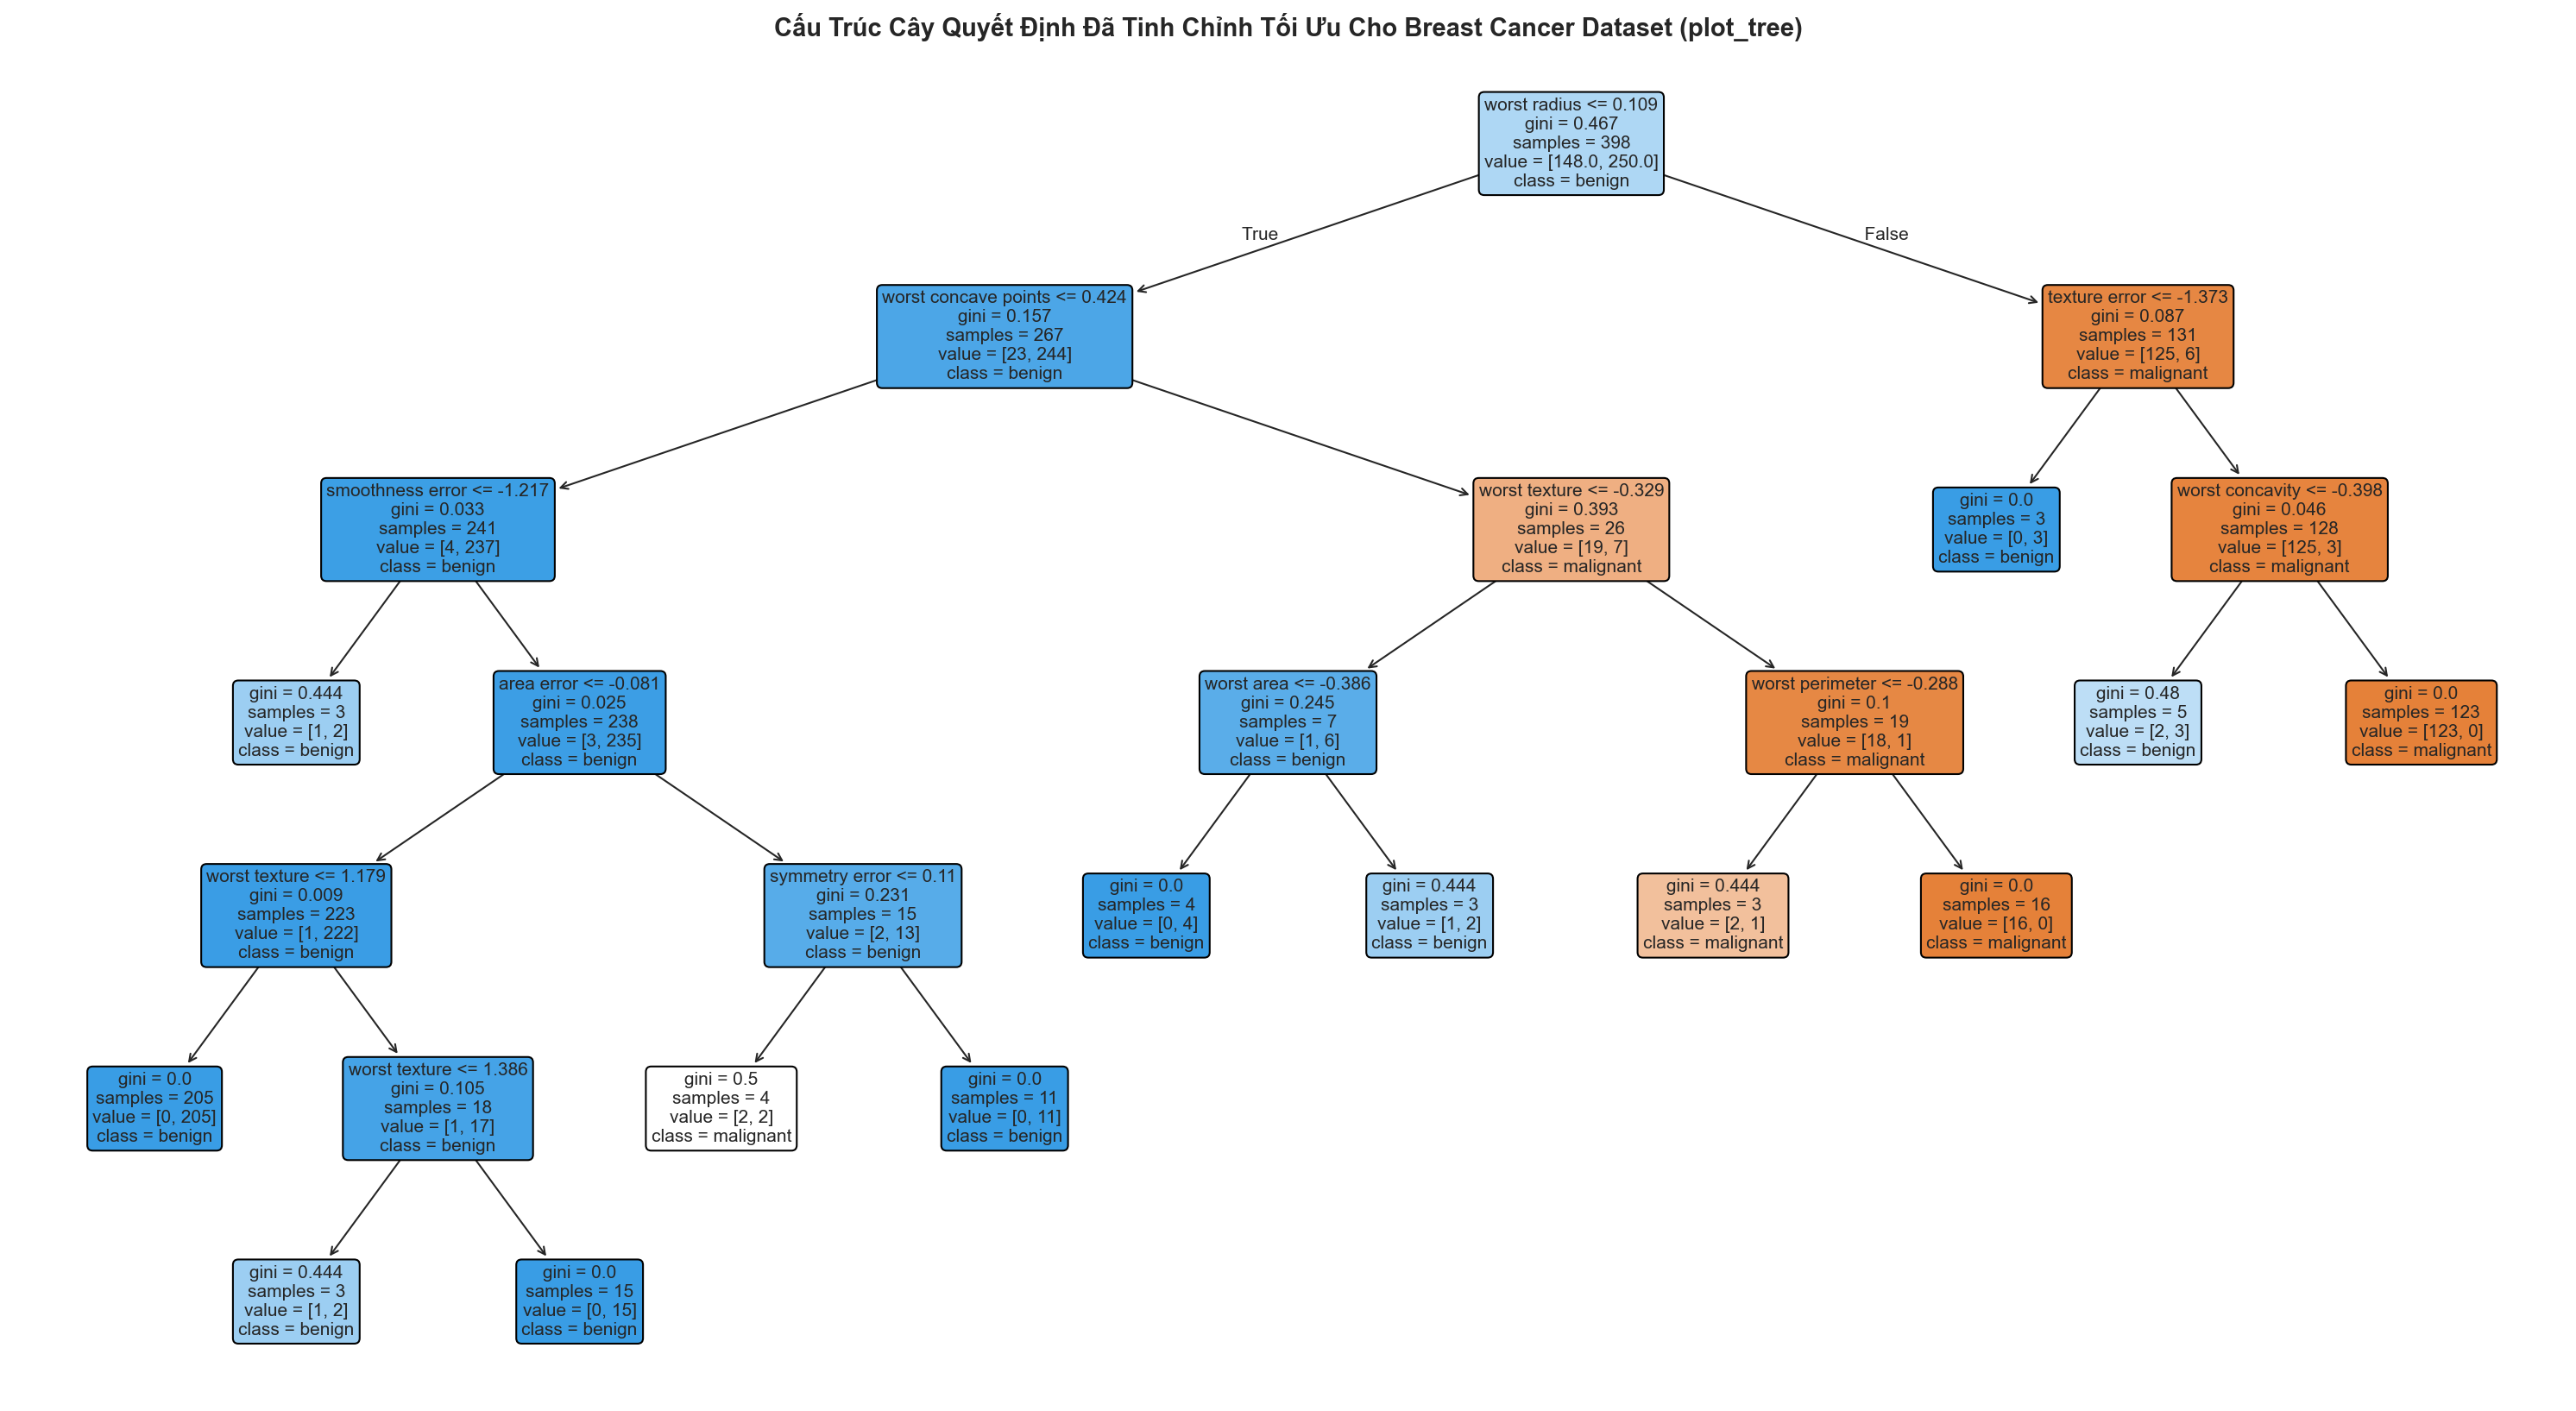

Đã kết xuất cây quyết định tối ưu bằng Graphviz thành file 'cancer_tuned_decision_tree.png' thành công!

=== CÁC TẬP LUẬT QUYẾT ĐỊNH TỐI ƯU TRÊN BREAST CANCER DATASET (OPTIMAL TEXT RULES) ===
|--- worst radius <= 0.11
|   |--- worst concave points <= 0.42
|   |   |--- smoothness error <= -1.22
|   |   |   |--- class: 1
|   |   |--- smoothness error >  -1.22
|   |   |   |--- area error <= -0.08
|   |   |   |   |--- worst texture <= 1.18
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- worst texture >  1.18
|   |   |   |   |   |--- worst texture <= 1.39
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- worst texture >  1.39
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- area error >  -0.08
|   |   |   |   |--- symmetry error <= 0.11
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- symmetry error >  0.11
|   |   |   |   |   |--- class: 1
|   |--- worst concave points >  0.42
|   |   |--- worst texture <= -0.33
|   |   |   |--- worst area <= -0.39
|   |   |

In [10]:
# 9.1. Trực quan hóa cây quyết định tối ưu bằng Matplotlib (plot_tree)
plt.figure(figsize=(20, 11), dpi=150)
plot_tree(
    best_model,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=10,
    impurity=True
)
plt.title("Cấu Trúc Cây Quyết Định Đã Tinh Chỉnh Tối Ưu Cho Breast Cancer Dataset (plot_tree)", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

# 9.2. Trực quan hóa cây quyết định tối ưu bằng Graphviz
dot_data_cancer = export_graphviz(
    best_model,
    out_file=None,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    special_characters=True
)

# Lưu file .dot và render file ảnh png
with open("cancer_tuned_decision_tree.dot", "w", encoding="utf-8") as f:
    f.write(dot_data_cancer)

try:
    graph = graphviz.Source(dot_data_cancer)
    graph.render("cancer_tuned_decision_tree", format="png", cleanup=True)
    print("Đã kết xuất cây quyết định tối ưu bằng Graphviz thành file 'cancer_tuned_decision_tree.png' thành công!")
except Exception as e:
    print("Lưu ý Graphviz:", e)

# 9.3. Hiển thị các luật quyết định tối ưu dạng văn bản (Text Rules)
print("\n=== CÁC TẬP LUẬT QUYẾT ĐỊNH TỐI ƯU TRÊN BREAST CANCER DATASET (OPTIMAL TEXT RULES) ===")
print(export_text(best_model, feature_names=list(feature_names)))
